In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

# Vector Spaces

Imagine a case in which a state space is defined in two dimensions. If three measurements are made, corresponding to three vectors $\vec{k_1}$, $\vec{k_2}$ and $\vec{k_3}$, the measurements $\vec{y_1}$, $\vec{y_2}$ and $\vec{y_3}$ are the orthogonal projections of $\vec{x}$ onto $\vec{k}$'s. Trivially the measurement is overconstrained.

In this example the measurement space is three dimensional, but the state space maps onto a subspace of the measurement space (a 2D plane), as one measurement is always a function of the other two. In the absence of measurement error, there will be points in the measurment space that fall out of the subspace (observe diagram). There correspond to impossible state vectors. 

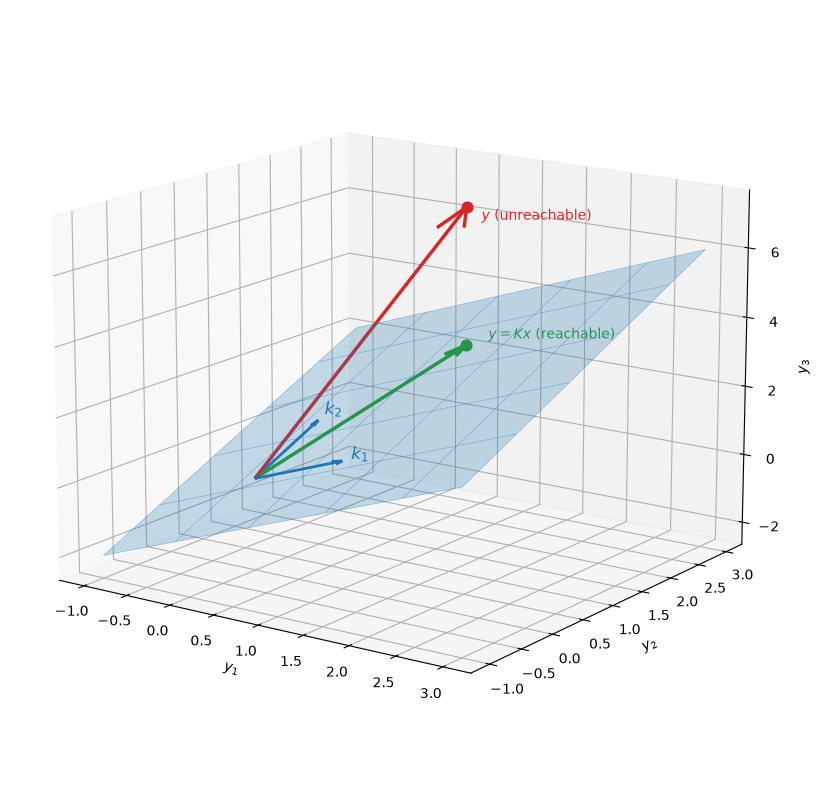

In [19]:
K = np.array([[1, 0],
              [0, 1],
              [1, 1]])

x = np.array([1, 2])

y_reachable = K @ x
y_unreachable = np.array([1, 2, 7])

s, t = np.meshgrid(np.linspace(-1, 3, 20), np.linspace(-1, 3, 20))
P = K @ np.vstack([s.ravel(), t.ravel()])
X, Y, Z = (P[i].reshape(s.shape) for i in range(3))

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection="3d")

ax.plot_surface(X, Y, Z, alpha=0.25, color="tab:blue", edgecolor="none")
ax.plot_wireframe(X, Y, Z, rstride=4, cstride=4, color="tab:blue",
                  linewidth=0.4, alpha=0.5)

o = np.zeros(3)
for col, name in zip(K.T, ["$k_1$", "$k_2$"]):
    ax.quiver(*o, *col, color="tab:blue", linewidth=2, arrow_length_ratio=0.1)
    ax.text(*(col * 1.1), name, color="tab:blue", fontsize=12)

ax.quiver(*o, *y_reachable, color="tab:green", linewidth=2.5,
          arrow_length_ratio=0.08)
ax.scatter(*y_reachable, color="tab:green", s=60)
ax.text(*(y_reachable + 0.15), r"$y = Kx$ (reachable)", color="tab:green")

ax.quiver(*o, *y_unreachable, color="tab:red", linewidth=2.5,
          arrow_length_ratio=0.08)
ax.scatter(*y_unreachable, color="tab:red", s=60)
ax.text(*(y_unreachable + np.array([0.1, 0.1, -0.4])),
        r"$y$ (unreachable)", color="tab:red")

ax.set_xlabel("$y_1$")
ax.set_ylabel("$y_2$")
ax.set_zlabel("$y_3$")
ax.view_init(elev=15, azim=-55)

plt.tight_layout()
plt.savefig(os.getcwd() + "/data/state_v_measurement.png", dpi=150)
plt.show()

# Identifying the null space and the row space

[10 15 20 25 30 35 40 45 50 55 60 65 70 75]
(14, 1000)


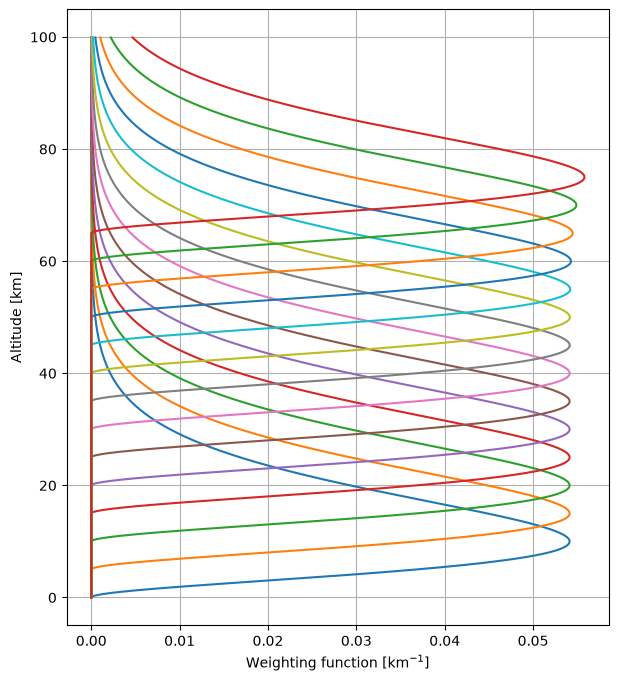

In [41]:
altitude = np.arange(0, 100, 0.1, dtype=float)

centers = np.arange(10,80,5)
print(centers)

n = 2
theta = 5.0

weighting_functions = []

for center in centers:

    x = altitude - (center - n * theta)

    K = np.zeros_like(altitude)
    mask = x >= 0
    K[mask] = x[mask]**n * np.exp(-x[mask] / theta)

    K /= np.trapezoid(K, altitude)
    weighting_functions.append(K)

weighting_functions = np.array(weighting_functions)
print(weighting_functions.shape)

plt.figure(figsize=(7, 8))

for center, K in zip(centers, weighting_functions):
    plt.plot(K, altitude, label=f'{center} km')

plt.xlabel('Weighting function [km$^{-1}$]')
plt.ylabel('Altitude [km]')
plt.grid()
plt.savefig(os.getcwd() + "/data/weighting_functions.png")
plt.show()

In [42]:
weighting_functions.shape

(14, 1000)

In [43]:
U, s, Vh = la.svd(weighting_functions)

In [44]:
U.shape

(14, 14)

In [45]:
Vh.shape

(1000, 1000)

In [46]:
s.shape

(14,)

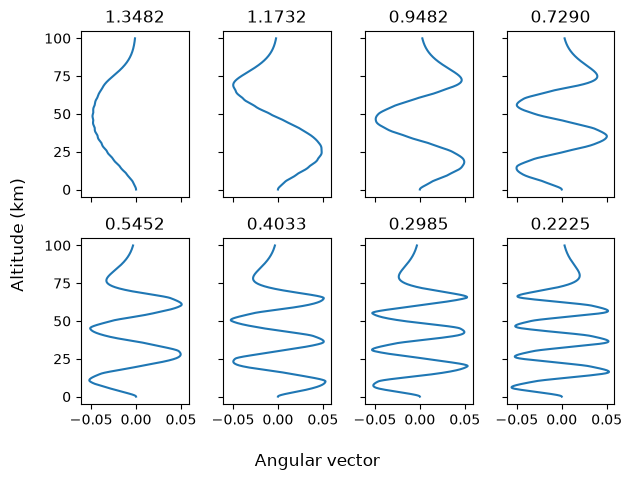

In [50]:
fig, axs = plt.subplots(nrows=2, ncols=4, sharex=True, sharey=True)
axs = axs.flatten()

for i in range(len(axs)):
    axs[i].plot(Vh.T[:, i], altitude)
    axs[i].set_title(f"{s[i]:.4f}")

fig.supxlabel("Angular vector")
fig.supylabel("Altitude (km)")

fig.tight_layout()
plt.savefig(os.getcwd() + "/data/weighting_function_svd.png")